### Plot MVA composite plot and force free fit.

In [1]:
import os
import re
import glob
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

from matplotlib.ticker import AutoMinorLocator
from scipy.special import jv
from lmfit import Parameters, minimize, report_fit

from JunoPy.mag import MagData, mva
from JunoPy.waves import WavesData
from JunoPy.library import find_ticks_between
from JunoPy.spice import InitSpiceKernels, get_juno_position

### 1. Functions to generate a force free fit.

In [2]:
def model_flux_rope(params, t, eTraj):
    """Creates a flux rope based on parameters."""
    alpha = params['alpha']
    IF = params['IF']
    thetaA = params['thetaA']
    phiA = params['phiA']
    B0 = params['B0']
    
    x = 2 * t * np.sqrt(1 - IF**2)
    r = np.sqrt(IF**2 + x**2)
    
    eZ = np.zeros(3)
    eZ[0] = np.sin(thetaA) * np.cos(phiA)
    eZ[1] = np.sin(thetaA) * np.sin(phiA)
    eZ[2] = np.cos(thetaA)
    
    eY = np.cross(eZ, eTraj)
    eX = np.cross(eY, eZ)
        
    eTrajTangent = eTraj - np.dot(eTraj, eZ) * eZ
    
    B = np.zeros((len(x), 3))
    for i, xi in enumerate(x):
        gamma = np.arctan2(xi, IF)
        eTangent = eTrajTangent * np.cos(gamma) + \
                   np.cross(eZ, eTrajTangent) * np.sin(gamma) + \
                   eZ * np.dot(eZ, eTrajTangent) * (1 - np.cos(gamma))
                   # Rodrigues' Formula

        B_a = B0 * jv(0, alpha * r[i])
        B_t = B0 * jv(1, alpha * r[i])
    
        B[i, :] = B_a * eZ + B_t * eTangent

    return B[:, 0], B[:, 1], B[:, 2]


def init_params(mvadata):
    """
    Initialize flux rope parameters.
    """
    thetaA = np.arccos(mvadata.x2[2])
    phiA = np.arctan2(mvadata.x2[1], mvadata.x2[0])
    
    eTraj = np.zeros(3)
    eTraj[0] = mvadata.df['X'][-1] - mvadata.df['X'][0]
    eTraj[1] = mvadata.df['Y'][-1] - mvadata.df['Y'][0]
    eTraj[2] = mvadata.df['Z'][-1] - mvadata.df['Z'][0]

    start = mvadata.df.index[0]
    end = mvadata.df.index[-1]
    mid = start + (end - start) / 2
    T0 = (end - start).total_seconds()
    
    Ti = list()
    for time, row in mvadata.df.iterrows():
        Ti.append((time - mid).total_seconds() / T0)
        
    Ti = np.asarray(Ti)
    
    initParams = Parameters()
    initParams.add('alpha', value=2.4048, min=-2.4048, max=2.4048)
    initParams.add('B0', value=1.0, vary=False)
    initParams.add('IF', value=0.5, min=0., max=1.)
    initParams.add('thetaA', value=thetaA, min=0., max=np.pi)
    initParams.add('phiA', value=phiA, min=-np.pi, max=np.pi)
    
    return Ti, initParams, T0, mid


def objective(params, t, magdata, eTraj):
    """Objective function to minimize."""
    Bx, By, Bz = model_flux_rope(params, t, eTraj)
    
    residuals = np.zeros((3, len(Bx)))
    residuals[0, :] = Bx - magdata.df['Bx'].values
    residuals[1, :] = By - magdata.df['By'].values
    residuals[2, :] = Bz - magdata.df['Bz'].values
    
    # return np.abs(residuals).flatten()
    return np.sum(np.sum(residuals**2, axis=0)) / len(Bx)
    
    
def read_and_crop(magfile, start, end):
    """Read and crop magnetometer data."""
    magdata = MagData(filename=magfile)
    start_cut = start - dt.timedelta(minutes=5)
    end_cut   = end   + dt.timedelta(minutes=5)
    magdata.df = magdata.df.loc[start_cut:end_cut]

    magdata_mva = MagData(filename=magfile)
    magdata_mva.df = magdata_mva.df.loc[start:end]
    magdata_mva = mva(magdata_mva)

    # print(magdata)
    return magdata, magdata_mva

### 2. Define main function for force free fit.

In [3]:
def force_free_fit_main(start, end):
    """Main function for force free fit."""
    magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
    magdata, magdata_mva = read_and_crop(magfile, start, end)
    
    magdata_mva.df['Bmag_saved'] = magdata_mva.df['Bmag']
    magdata_mva.df['Bx'] /= magdata_mva.df['Bmag']
    magdata_mva.df['By'] /= magdata_mva.df['Bmag']
    magdata_mva.df['Bz'] /= magdata_mva.df['Bmag']
    
    Ti, initParams, T0, mid = init_params(magdata_mva)

    eTraj = np.zeros(3)
    eTraj[0] = magdata_mva.df['X'][-1] - magdata_mva.df['X'][0]
    eTraj[1] = magdata_mva.df['Y'][-1] - magdata_mva.df['Y'][0]
    eTraj[2] = magdata_mva.df['Z'][-1] - magdata_mva.df['Z'][0]
    eTraj = eTraj / np.linalg.norm(eTraj)

    out = minimize(objective, initParams, args=(Ti, magdata_mva, eTraj), method='ampgo')
    
    fitParams = Parameters()
    fitParams.add('alpha', value=out.params['alpha'].value, vary=False)
    fitParams.add('B0', value=1.0, vary=True)
    fitParams.add('IF', value=out.params['IF'].value, vary=False)
    fitParams.add('thetaA', value=out.params['thetaA'].value, vary=False)
    fitParams.add('phiA', value=out.params['phiA'].value, vary=False)
    
    magdata_mva.df['Bx'] *= magdata_mva.df['Bmag']
    magdata_mva.df['By'] *= magdata_mva.df['Bmag']
    magdata_mva.df['Bz'] *= magdata_mva.df['Bmag']
    
    out2 = minimize(objective, fitParams, args=(Ti, magdata_mva, eTraj), method='cg')
    
    
    Bx_fit, By_fit, Bz_fit = model_flux_rope(out2.params, Ti, eTraj)
    B_fit = np.asarray([Bx_fit, By_fit, Bz_fit]).T
    B1_fit = np.dot(B_fit, np.asarray([magdata_mva.x1, magdata_mva.x2, magdata_mva.x3]).T)
    
    return magdata, magdata_mva, B1_fit, out, out2

In [4]:
# start = dt.datetime.strptime('2017-338T01:49:57', '%Y-%jT%H:%M:%S')
# end   = dt.datetime.strptime('2017-338T01:51:00', '%Y-%jT%H:%M:%S')

start = dt.datetime.strptime('2017-236T20:21:15', '%Y-%jT%H:%M:%S')
end   = dt.datetime.strptime('2017-236T20:21:38', '%Y-%jT%H:%M:%S')

# start = dt.datetime.strptime('2019-089T20:35:47', '%Y-%jT%H:%M:%S')
# end   = dt.datetime.strptime('2019-089T20:36:36', '%Y-%jT%H:%M:%S')

# start = dt.datetime.strptime('2019-089T20:16:40', '%Y-%jT%H:%M:%S')
# end   = dt.datetime.strptime('2019-089T20:16:59', '%Y-%jT%H:%M:%S')

# start = dt.datetime.strptime('2017-186T20:16:40', '%Y-%jT%H:%M:%S')
# end   = dt.datetime.strptime('2017-186T20:16:59', '%Y-%jT%H:%M:%S')
magdata, magdata_mva, B1_fit, out0, out = force_free_fit_main(start, end)

### 3. Plot the composite plot.

In [5]:
def plot_mva_composite(magdata, magdata_mva, start, end, B1_fit, savefile=False):

    fig = plt.figure(figsize=(11, 8.5), constrained_layout=False, dpi=300)

    gs1 = fig.add_gridspec(
        nrows=4, ncols=1, top=0.99, bottom=0.55, left=0.15, right=0.7, hspace=0)
    ax_magdata = list()
    for i in range(4):
        ax_magdata.append(fig.add_subplot(gs1[i, 0]))

    gs2 = fig.add_gridspec(
        nrows=3, ncols=1, top=0.45, bottom=0.1, left=0.15, right=0.66, hspace=0)
    ax_mvaB = list()
    for i in range(3):
        ax_mvaB.append(fig.add_subplot(gs2[i, 0]))

    gs3 = fig.add_gridspec(
        nrows=2, ncols=1, top=0.45, bottom=0.1, left=0.67, right=0.9, hspace=0)
    ax_hodo = list()
    for i in range(2):
        ax_hodo.append(fig.add_subplot(gs3[i, 0]))

    gs4 = fig.add_gridspec(
        nrows=1, ncols=1, top=0.9, bottom=0.55, left=0.71, right=0.9)
    ax_text = fig.add_subplot(gs4[0, 0])

    # 1. Plot the mag data +/- 10 min from epoch. ------------------------------------
    ax_magdata = magdata.plot(
        vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=ax_magdata)
    timearray, tickstring = find_ticks_between(magdata.df.index[0], magdata.df.index[-1])
    ylabels = ['B$_r$', 'B$_\\theta$', 'B$_\phi$', '|B|']
    for i, a in enumerate(ax_magdata):
        a.set_xticks([], [])
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.set_ylabel(ylabels[i] + ' (nT)')
        a.set_xlim(magdata.df.index[0], magdata.df.index[-1])
        a.label_outer()
        if start and end:
            a.axvspan(start, end, alpha=0.2, color=[0.2, 0.2, 0.2])
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)


    # 2. Plot the MVA B vectors. -------------------------------------------------------
    ax_mvaB = magdata_mva.plot(vars=['B1', 'B2', 'B3'], Bfit=B1_fit.T, axs=ax_mvaB)
    timearray2, tickstring2 = find_ticks_between(magdata_mva.df.index[0], magdata_mva.df.index[-1])
    ylabels = ['B$_1$', 'B$_2$', 'B$_3$']
    for i, a in enumerate(ax_mvaB):
        a.set_xticks([], [])
        a.set_xticks(timearray2)
        a.set_xticklabels(tickstring2, fontdict={'horizontalalignment':'right'})
        a.set_xlim(magdata_mva.df.index[0], magdata_mva.df.index[-1])
        a.set_ylabel(ylabels[i] + ' (nT)')
        a.label_outer()
        
    ax_mvaB[0].legend(['Data', 'Model'], loc='upper left')
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)

    dy = (ax_mvaB[-1].get_ylim()[1] - ax_mvaB[-1].get_ylim()[0]) / 2
    
    ax_mvaB[0].set_ylim([magdata_mva.df['B1'].mean() - dy,
                         magdata_mva.df['B1'].mean() + dy])
    ax_mvaB[1].set_ylim([magdata_mva.df['B2'].mean() - dy,
                         magdata_mva.df['B2'].mean() + dy])
    
    # 3. Plot the hodograms. -----------------------------------------------------------
    combo = [['B3', 'B1'],
             ['B3', 'B2']]
    Bmax = np.max(np.array(
            [magdata_mva.df['B1'].abs().max(), 
             magdata_mva.df['B2'].abs().max(), 
             magdata_mva.df['B3'].abs().max()]))  * 1.01
    
    
    for i, a in enumerate(ax_hodo):
        
        a.scatter(magdata_mva.df[combo[i][0]][0], magdata_mva.df[combo[i][1]][0], marker='o', color='b', s=50, label='Start')
        a.scatter(magdata_mva.df[combo[i][0]][-1], magdata_mva.df[combo[i][1]][-1], marker='x', color='r', s=50, label='End')
        a.plot(magdata_mva.df[combo[i][0]], magdata_mva.df[combo[i][1]],
               color='k',lw=0.4)
        
        a.set_xlabel(combo[i][0] + ' (nT)')
        a.set_ylabel(combo[i][1] + ' (nT)')
        a.set_aspect('equal', adjustable='datalim')
        a.xaxis.set_minor_locator(AutoMinorLocator())
        a.yaxis.set_minor_locator(AutoMinorLocator())
        a.grid('on', which='minor', lw=0.5, ls='dotted')
        a.grid(color='k', ls='dashed', lw=0.25)
        a.yaxis.tick_right()
        a.yaxis.set_label_position("right")
        a.label_outer()
    
    ax_hodo[0].legend(loc='upper right')
    ax_hodo[0].set_xlabel('B$_3$ (nT)')
    ax_hodo[0].set_ylabel('B$_1$ (nT)')
    ax_hodo[1].set_xlabel('B$_3$ (nT)')
    ax_hodo[1].set_ylabel('B$_2$ (nT)')
        
    # 4. Add Text ----------------------------------------------------------------------
    ax_text.axis('off')

    date = dt.datetime.strptime(start.strftime('%Y-%j'), '%Y-%j')

    text = []
    text.append(dt.datetime.strftime(date, '%Y-%m-%d') + ', DOY={:s}'.format(dt.datetime.strftime(date, '%j')))
    text.append('\n\n')
    text.append('MVA Output:\n--------\n\nCartesian Eigenvectors:\n')
    text.append('x$_1$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x1[0], magdata_mva.x1[1], magdata_mva.x1[2]))
    text.append('x$_2$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x2[0], magdata_mva.x2[1], magdata_mva.x2[2]))
    text.append('x$_3$ = ({:.2f}, {:.2f}, {:.2f})\n\n'.format(magdata_mva.x3[0], magdata_mva.x3[1], magdata_mva.x3[2]))
    text.append('--------\nRatio of eigenvalues:\n')
    text.append('$\lambda_3$ / $\lambda_2$ = {:.2f}\n'.format(magdata_mva.eigval[2] / magdata_mva.eigval[1]))
    text.append('$\lambda_2$ / $\lambda_1$ = {:.2f}\n'.format(magdata_mva.eigval[1] / magdata_mva.eigval[0]))
    text = ''.join(text)
    ax_text.text(0.5, 0.5, text, horizontalalignment='center', verticalalignment='center',
                 bbox=dict(boxstyle="round",
                   ec=(0.9, 0.9, 0.9),
                   fc=(0.9, 0.9, 0.9),
                   ))
    
    if savefile:
        plotfile = 'out_mva/' + dt.datetime.strftime(start, '%Y-%jT%H:%M:%S') + '_fitted'
        fig.savefig(plotfile)
        plt.close(fig)

/Users/sarkango/.virtualenvs/JunoPy/lib/python3.7/site-packages/ipykernel-5.2.0-py3.7.egg/ipykernel_launcher.py:33: MatplotlibDeprecationWarning: Passing the minor parameter of set_xticks() positionally is deprecated since Matplotlib 3.2; the parameter will become keyword-only two minor releases later.
/Users/sarkango/.virtualenvs/JunoPy/lib/python3.7/site-packages/ipykernel-5.2.0-py3.7.egg/ipykernel_launcher.py:50: MatplotlibDeprecationWarning: Passing the minor parameter of set_xticks() positionally is deprecated since Matplotlib 3.2; the parameter will become keyword-only two minor releases later.


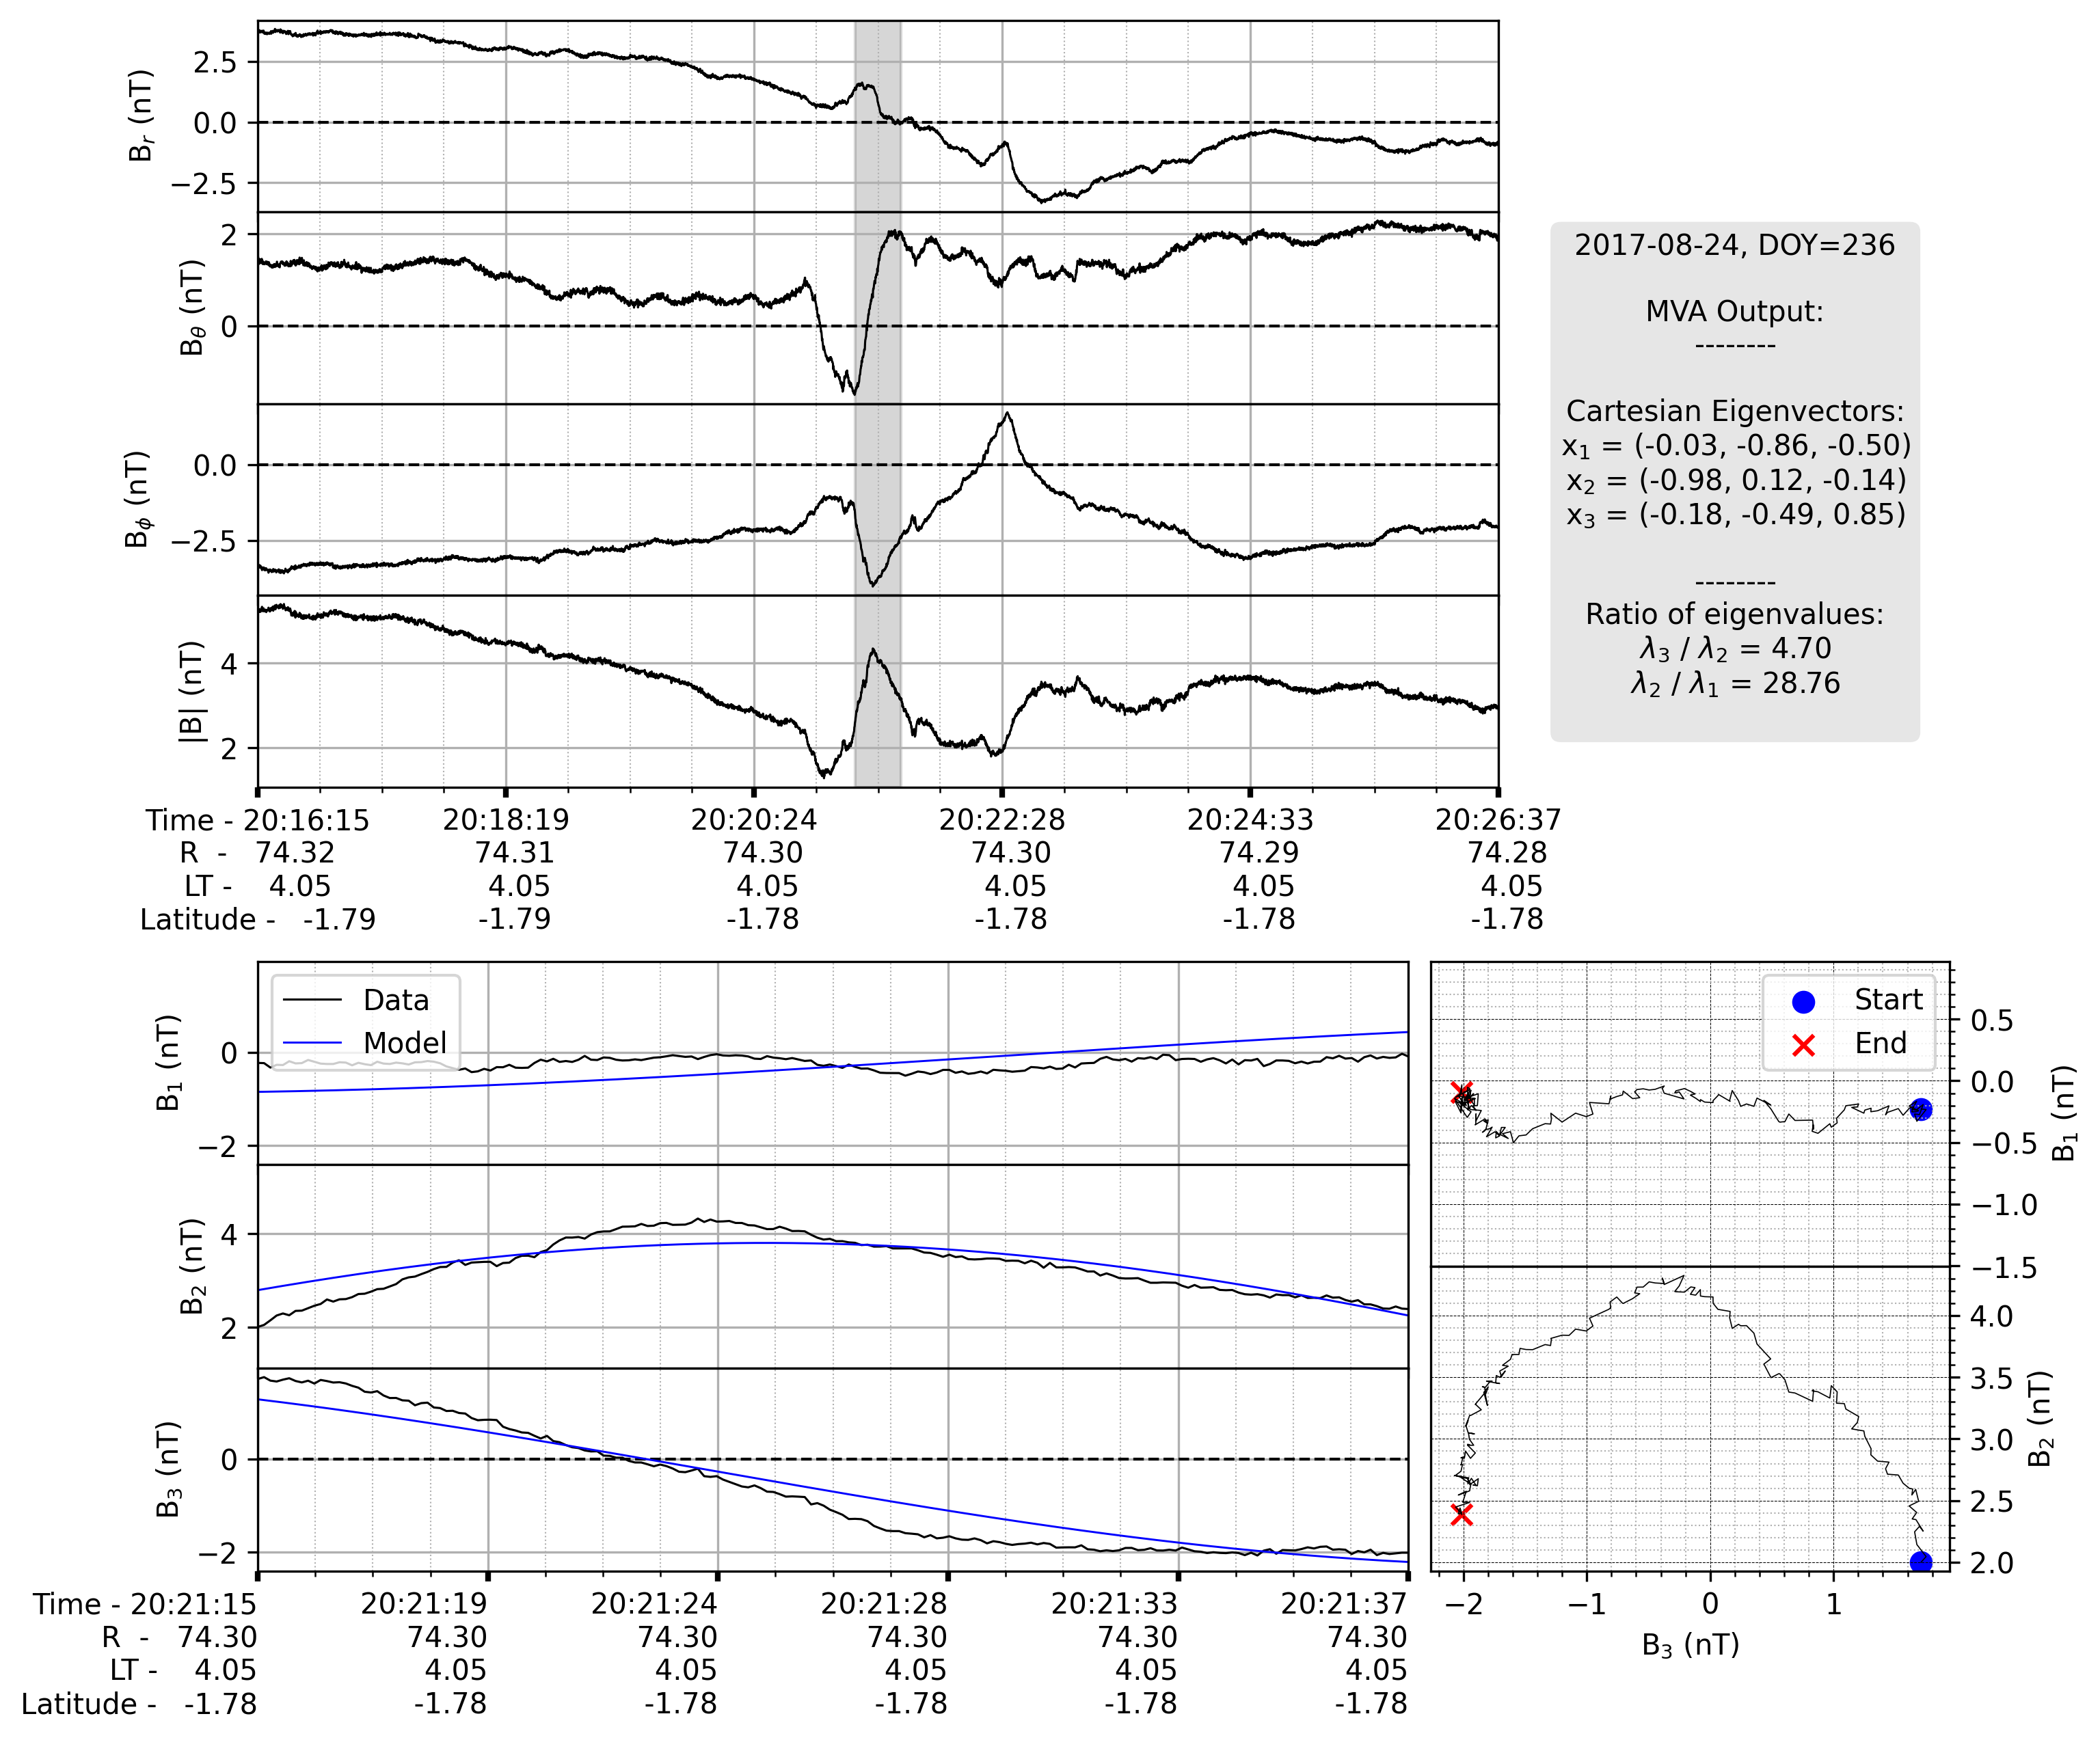

In [6]:
plot_mva_composite(magdata, magdata_mva, start, end, B1_fit, savefile=False)

In [7]:
out0

# Fetch the Waves data for this interval.

In [8]:
try:
    wavesfile = glob.glob('data/waves-survey/*{:s}*_E_V01.CSV'.format(start.strftime('%Y%j')))[0]
    wavesdata = WavesData(filename=wavesfile)
    
except IndexError:
    wavesindex = IndexFile(dataset='waves-survey')
    wavesindex.get_files_between_dates(
        start, end, DoDownload=True)
    wavesfile = glob.glob('data/waves-survey/*{:s}*_E_V01.CSV'.format(start.strftime('%Y%j')))[0]
    wavesdata = WavesData(filename=wavesfile)

In [9]:
def plot_mva_composite_2(magdata, magdata_mva, wavesdata, start, end, B1_fit, savefile=False):

    fig = plt.figure(figsize=(11, 8.5), constrained_layout=False, dpi=300)

    gs1 = fig.add_gridspec(
        nrows=5, ncols=1, top=0.99, bottom=0.55, left=0.15, right=0.7, hspace=0)
    ax_magdata = list()
    for i in range(5):
        ax_magdata.append(fig.add_subplot(gs1[i, 0]))

    gs2 = fig.add_gridspec(
        nrows=3, ncols=1, top=0.45, bottom=0.1, left=0.15, right=0.66, hspace=0)
    ax_mvaB = list()
    for i in range(3):
        ax_mvaB.append(fig.add_subplot(gs2[i, 0]))

    gs3 = fig.add_gridspec(
        nrows=2, ncols=1, top=0.45, bottom=0.1, left=0.67, right=0.9, hspace=0)
    ax_hodo = list()
    for i in range(2):
        ax_hodo.append(fig.add_subplot(gs3[i, 0]))

    gs4 = fig.add_gridspec(
        nrows=1, ncols=1, top=0.9, bottom=0.55, left=0.71, right=0.9)
    ax_text = fig.add_subplot(gs4[0, 0])

    # 1. Plot the mag data +/- 10 min from epoch. ------------------------------------
    ax_magdata[:-1] = magdata.plot(
        vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=ax_magdata[:-1])
    ax_magdata[-1] = wavesdata.plot(ax_magdata[-1], freqlimit=True, vmin=1e-15, vmax=1e-12)
    
    timearray, tickstring = find_ticks_between(magdata.df.index[0], magdata.df.index[-1])
    ylabels = ['B$_r$ (nT)', 'B$_\\theta$ (nT)', 'B$_\phi$ (nT)', '|B| (nT)', 'Freq (Hz)']
    for i, a in enumerate(ax_magdata):
        a.set_xticks([], [])
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.set_ylabel(ylabels[i])
        a.set_xlim(magdata.df.index[0], magdata.df.index[-1])
        a.label_outer()
        
            # a.axvspan(start, end, alpha=0.2, color=[0.2, 0.2, 0.2])
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)
    ax_magdata[-1].set_yticks([1000, 10000])

    for a in ax_magdata[:-1]:
        if start and end:
            a.axvspan(start, end, alpha=0.2, color=[0.2, 0.2, 0.2])
    if start and end:
        ax_magdata[-1].axvline(start, color='magenta', ls='dashed')
        ax_magdata[-1].axvline(end, color='magenta', ls='dashed')
            
    # 2. Plot the MVA B vectors. -------------------------------------------------------
    ax_mvaB = magdata_mva.plot(vars=['B1', 'B2', 'B3'], Bfit=B1_fit.T, axs=ax_mvaB)
    timearray2, tickstring2 = find_ticks_between(magdata_mva.df.index[0], magdata_mva.df.index[-1])
    ylabels = ['B$_1$', 'B$_2$', 'B$_3$']
    for i, a in enumerate(ax_mvaB):
        a.set_xticks([], [])
        a.set_xticks(timearray2)
        a.set_xticklabels(tickstring2, fontdict={'horizontalalignment':'right'})
        a.set_xlim(magdata_mva.df.index[0], magdata_mva.df.index[-1])
        a.set_ylabel(ylabels[i] + ' (nT)')
        a.label_outer()
        
    ax_mvaB[0].legend(['Data', 'Model'], loc='upper left')
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)

    dy = (ax_mvaB[-1].get_ylim()[1] - ax_mvaB[-1].get_ylim()[0]) / 2
    
    ax_mvaB[0].set_ylim([magdata_mva.df['B1'].mean() - dy,
                         magdata_mva.df['B1'].mean() + dy])
    ax_mvaB[1].set_ylim([magdata_mva.df['B2'].mean() - dy,
                         magdata_mva.df['B2'].mean() + dy])
    
    # 3. Plot the hodograms. -----------------------------------------------------------
    combo = [['B3', 'B1'],
             ['B3', 'B2']]
    Bmax = np.max(np.array(
            [magdata_mva.df['B1'].abs().max(), 
             magdata_mva.df['B2'].abs().max(), 
             magdata_mva.df['B3'].abs().max()]))  * 1.01
    
    
    for i, a in enumerate(ax_hodo):
        
        a.scatter(magdata_mva.df[combo[i][0]][0], magdata_mva.df[combo[i][1]][0], marker='o', color='b', s=50, label='Start')
        a.scatter(magdata_mva.df[combo[i][0]][-1], magdata_mva.df[combo[i][1]][-1], marker='x', color='r', s=50, label='End')
        a.plot(magdata_mva.df[combo[i][0]], magdata_mva.df[combo[i][1]],
               color='k',lw=0.4)
        
        a.set_xlabel(combo[i][0] + ' (nT)')
        a.set_ylabel(combo[i][1] + ' (nT)')
        a.set_aspect('equal', adjustable='datalim')
        a.xaxis.set_minor_locator(AutoMinorLocator())
        a.yaxis.set_minor_locator(AutoMinorLocator())
        a.grid('on', which='minor', lw=0.5, ls='dotted')
        a.grid(color='k', ls='dashed', lw=0.25)
        a.yaxis.tick_right()
        a.yaxis.set_label_position("right")
        a.label_outer()
    
    ax_hodo[0].legend(loc='upper left')
    ax_hodo[0].set_xlabel('B$_3$ (nT)')
    ax_hodo[0].set_ylabel('B$_1$ (nT)')
    ax_hodo[1].set_xlabel('B$_3$ (nT)')
    ax_hodo[1].set_ylabel('B$_2$ (nT)')
        
    # 4. Add Text ----------------------------------------------------------------------
    ax_text.axis('off')

    date = dt.datetime.strptime(start.strftime('%Y-%j'), '%Y-%j')

    text = []
    text.append(dt.datetime.strftime(date, '%Y-%m-%d') + ', DOY={:s}'.format(dt.datetime.strftime(date, '%j')))
    text.append('\n\n')
    text.append('MVA Output:\n--------\n\nCartesian Eigenvectors:\n')
    text.append('x$_1$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x1[0], magdata_mva.x1[1], magdata_mva.x1[2]))
    text.append('x$_2$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x2[0], magdata_mva.x2[1], magdata_mva.x2[2]))
    text.append('x$_3$ = ({:.2f}, {:.2f}, {:.2f})\n\n'.format(magdata_mva.x3[0], magdata_mva.x3[1], magdata_mva.x3[2]))
    text.append('--------\nRatio of eigenvalues:\n')
    text.append('$\lambda_3$ / $\lambda_2$ = {:.2f}\n'.format(magdata_mva.eigval[2] / magdata_mva.eigval[1]))
    text.append('$\lambda_2$ / $\lambda_1$ = {:.2f}\n'.format(magdata_mva.eigval[1] / magdata_mva.eigval[0]))
    text = ''.join(text)
    ax_text.text(0.5, 0.75, text, horizontalalignment='center', verticalalignment='center',
                 bbox=dict(boxstyle="round",
                   ec=(0.9, 0.9, 0.9),
                   fc=(0.9, 0.9, 0.9),
                   ))
    
    ax_magdata[0].text(0.96, 0.8, 'a)', transform=ax_magdata[0].transAxes, weight='bold')
    ax_magdata[1].text(0.96, 0.8, 'b)', transform=ax_magdata[1].transAxes, weight='bold')
    ax_magdata[2].text(0.96, 0.8, 'c)', transform=ax_magdata[2].transAxes, weight='bold')
    ax_magdata[3].text(0.96, 0.8, 'd)', transform=ax_magdata[3].transAxes, weight='bold')
    ax_magdata[4].text(0.96, 0.8, 'e)', transform=ax_magdata[4].transAxes, weight='bold')
    ax_mvaB[0].text(0.96, 0.8, 'f)', transform=ax_mvaB[0].transAxes, weight='bold')
    ax_mvaB[1].text(0.96, 0.8, 'g)', transform=ax_mvaB[1].transAxes, weight='bold')
    ax_mvaB[2].text(0.96, 0.8, 'h)', transform=ax_mvaB[2].transAxes, weight='bold')
    ax_hodo[0].text(0.9, 0.8, 'i)', transform=ax_hodo[0].transAxes, weight='bold')
    ax_hodo[1].text(0.9, 0.8, 'j)', transform=ax_hodo[1].transAxes, weight='bold')
    
    if savefile:
        plotfile = 'out_mva/' + dt.datetime.strftime(start, '%Y-%jT%H:%M:%S') + '_fitted_waves'
        fig.savefig(plotfile)
        plt.close(fig)

In [10]:
plot_mva_composite_2(magdata, magdata_mva, wavesdata, start, end, B1_fit, savefile=True)

/Users/sarkango/.virtualenvs/JunoPy/lib/python3.7/site-packages/ipykernel-5.2.0-py3.7.egg/ipykernel_launcher.py:35: MatplotlibDeprecationWarning: Passing the minor parameter of set_xticks() positionally is deprecated since Matplotlib 3.2; the parameter will become keyword-only two minor releases later.
/Users/sarkango/.virtualenvs/JunoPy/lib/python3.7/site-packages/ipykernel-5.2.0-py3.7.egg/ipykernel_launcher.py:59: MatplotlibDeprecationWarning: Passing the minor parameter of set_xticks() positionally is deprecated since Matplotlib 3.2; the parameter will become keyword-only two minor releases later.
/Users/sarkango/.virtualenvs/JunoPy/lib/python3.7/site-packages/matplotlib-3.2.1-py3.7-macosx-10.14-x86_64.egg/matplotlib/colors.py:1171: RuntimeWarning: invalid value encountered in less_equal
  mask |= resdat <= 0
